<a href="https://colab.research.google.com/github/amrithavi/GENE-PAPER/blob/main/RERUNDNA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q tensorflow pandas scikit-learn matplotlib seaborn

In [ ]:

import os
import zipfile
import re

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Embedding, LSTM, Dense, Dropout, Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
from sklearn.linear_model import LogisticRegression

print("TensorFlow:", tf.__version__)
print("Setup complete.")

TensorFlow: 2.21.0
Setup complete.


In [ ]:

from google.colab import files

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the ZIP file containing the CSV datasets.")

zip_path = zip_files[0]
print("Uploaded:", zip_path)


Saving archive (3) (1).zip to archive (3) (1) (2).zip
Uploaded: archive (3) (1) (2).zip


In [ ]:

data_dir = "/content/data"
os.makedirs(data_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_dir)

for root, dirs, filenames in os.walk(data_dir):
    for filename in filenames:
        print(os.path.join(root, filename))


/content/data/validation.csv
/content/data/test.csv
/content/data/train.csv


In [ ]:

def find_csv(filename):
    matches = []

    for root, dirs, filenames in os.walk(data_dir):
        if filename in filenames:
            matches.append(os.path.join(root, filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {filename}, found: {matches}"
        )

    return matches[0]


train_df = pd.read_csv(find_csv("train.csv"))
val_df = pd.read_csv(find_csv("validation.csv"))
test_df = pd.read_csv(find_csv("test.csv"))

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nColumns:", train_df.columns.tolist())
train_df.head()


Train: (22593, 7)
Validation: (4577, 7)
Test: (8326, 7)

Columns: ['Unnamed: 0', 'NCBIGeneID', 'Symbol', 'Description', 'GeneType', 'GeneGroupMethod', 'NucleotideSequence']


,Unnamed: 0,NCBIGeneID,Symbol,Description,GeneType,GeneGroupMethod,NucleotideSequence
0,0,106481178,RNU4-21P,"RNA, U4 small nuclear 21, pseudogene",PSEUDO,NCBI Ortholog,<AGCTTAGCACAGTGGCAGTATCATAGGCAGTGAGGTTTATCCGAG...
1,1,123477792,LOC123477792,Sharpr-MPRA regulatory region 12926,BIOLOGICAL_REGION,NCBI Ortholog,<CTGGAGCGGCCACGATGTGAACTGTCACCGGCCACTGCTGCTCCG...
2,2,113174975,LOC113174975,Sharpr-MPRA regulatory region 7591,BIOLOGICAL_REGION,NCBI Ortholog,<TTCCCAATTTTTCCTCTGCTTTTTAATTTTCTAGTTTCCTTTTTC...
3,3,116216107,LOC116216107,CRISPRi-validated cis-regulatory element chr10...,BIOLOGICAL_REGION,NCBI Ortholog,<CGCCCAGGCTGGAGTGCAGTGGCGCCATCTCGGCTCACTGCAGGC...
4,4,28502,IGHD2-21,immunoglobulin heavy diversity 2-21,OTHER,NCBI Ortholog,<AGCATATTGTGGTGGTGACTGCTATTCC>


In [ ]:

def clean_df(df):
    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])

    df = df.dropna().copy()
    return df


train_df = clean_df(train_df)
val_df = clean_df(val_df)
test_df = clean_df(test_df)

required_columns = ["NucleotideSequence", "Description", "GeneType"]

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    missing = set(required_columns) - set(df.columns)

    if missing:
        raise ValueError(f"{name} dataset is missing columns: {missing}")

print("After cleaning:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


After cleaning:
Train: (22593, 6)
Validation: (4577, 6)
Test: (8326, 6)


In [ ]:

train_df = train_df[
    train_df["GeneType"] != "scRNA"
].copy()

val_df = val_df[
    val_df["GeneType"] != "scRNA"
].copy()

test_df = test_df[
    test_df["GeneType"] != "scRNA"
].copy()

print("Training class distribution:")
print(train_df["GeneType"].value_counts())

print("\nDataset sizes after removing scRNA:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Training class distribution:
GeneType
PSEUDO               10220
BIOLOGICAL_REGION     6925
ncRNA                 2497
snoRNA                1148
PROTEIN_CODING         524
tRNA                   488
OTHER                  366
rRNA                   277
snRNA                  145
Name: count, dtype: int64

Dataset sizes after removing scRNA:
Train: 22590
Validation: 4577
Test: 8325


In [ ]:

MAX_LEN = 500

dna_tokenizer = Tokenizer(char_level=True)
dna_tokenizer.fit_on_texts(
    train_df["NucleotideSequence"]
)

X_train_seq = dna_tokenizer.texts_to_sequences(
    train_df["NucleotideSequence"]
)
X_val_seq = dna_tokenizer.texts_to_sequences(
    val_df["NucleotideSequence"]
)
X_test_seq = dna_tokenizer.texts_to_sequences(
    test_df["NucleotideSequence"]
)

X_train_seq = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)
X_val_seq = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)
X_test_seq = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Sequence shapes:")
print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)
print("Character vocabulary:", dna_tokenizer.word_index)


Sequence shapes:
(22590, 500)
(4577, 500)
(8325, 500)
Character vocabulary: {'a': 1, 't': 2, 'g': 3, 'c': 4, '<': 5, '>': 6}


In [ ]:

tfidf = TfidfVectorizer(max_features=3000)

X_train_text = tfidf.fit_transform(
    train_df["Description"]
).toarray()

X_val_text = tfidf.transform(
    val_df["Description"]
).toarray()

X_test_text = tfidf.transform(
    test_df["Description"]
).toarray()

print("TF-IDF shapes:")
print(X_train_text.shape)
print(X_val_text.shape)
print(X_test_text.shape)


TF-IDF shapes:
(22590, 3000)
(4577, 3000)
(8325, 3000)


In [ ]:

le = LabelEncoder()

y_train = le.fit_transform(train_df["GeneType"])
y_val = le.transform(val_df["GeneType"])
y_test = le.transform(test_df["GeneType"])

num_classes = len(le.classes_)

print("Classes:", list(le.classes_))
print("Number of classes:", num_classes)
print("Label shapes:", y_train.shape, y_val.shape, y_test.shape)

assert set(np.unique(y_val)).issubset(set(np.unique(y_train)))
assert set(np.unique(y_test)).issubset(set(np.unique(y_train)))


Classes: ['BIOLOGICAL_REGION', 'OTHER', 'PROTEIN_CODING', 'PSEUDO', 'ncRNA', 'rRNA', 'snRNA', 'snoRNA', 'tRNA']
Number of classes: 9
Label shapes: (22590,) (4577,) (8325,)


In [ ]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# DNA branch
seq_input = Input(shape=(MAX_LEN,), name="dna_input")

x = Embedding(
    input_dim=len(dna_tokenizer.word_index) + 1,
    output_dim=8
)(seq_input)

x = LSTM(64)(x)
x = Dropout(0.3)(x)

# TF-IDF branch
text_input = Input(
    shape=(X_train_text.shape[1],),
    name="text_input"
)

y = Dense(256, activation="relu")(text_input)
y = Dropout(0.3)(y)

# Fusion
combined = Concatenate()([x, y])

z = Dense(128, activation="relu")(combined)
z = Dropout(0.3)(z)

output = Dense(
    num_classes,
    activation="softmax"
)(z)

model = Model(
    inputs=[seq_input, text_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ dna_input           │ (None, 500)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 500, 8)    │         56 │ dna_input[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 3000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     18,688 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    768,256 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 320)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     41,088 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 9)         │      1,161 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 829,249 (3.16 MB)

 Trainable params: 829,249 (3.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

history = model.fit(
    [X_train_seq, X_train_text],
    y_train,
    validation_data=(
        [X_val_seq, X_val_text],
        y_val
    ),
    epochs=50,
    batch_size=64,
    verbose=1
)


Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.9020 - loss: 0.3717 - val_accuracy: 0.9755 - val_loss: 0.0738
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.9721 - loss: 0.0824 - val_accuracy: 0.9797 - val_loss: 0.0566
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9765 - loss: 0.0654 - val_accuracy: 0.9797 - val_loss: 0.0527
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9764 - loss: 0.0602 - val_accuracy: 0.9801 - val_loss: 0.0510
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9779 - loss: 0.0562 - val_accuracy: 0.9803 - val_loss: 0.0510
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9781 - loss: 0.0554 - val_accuracy: 0.9803 - val_loss: 0.0490
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9784 - loss: 0.0533 - val_accuracy: 0.9801 - val_loss: 0.0478
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9779 - loss: 0.0518 - val_ac

In [ ]:

pred = model.predict(
    [X_test_seq, X_test_text],
    verbose=0
)

pred_classes = np.argmax(pred, axis=1)

fused_accuracy = accuracy_score(y_test, pred_classes)

print(f"Fused model accuracy: {fused_accuracy:.6f}")
print(f"Fused model accuracy: {fused_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_classes,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Fused model accuracy: 0.982222
Fused model accuracy: 98.22%

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     1.0000    1.0000    1.0000      2651
            OTHER     0.9925    0.9925    0.9925       133
   PROTEIN_CODING     0.9882    0.9076    0.9462       184
           PSEUDO     0.9883    0.9745    0.9813      3800
            ncRNA     0.9867    0.9989    0.9928       894
             rRNA     1.0000    1.0000    1.0000        72
            snRNA     0.5312    0.8947    0.6667        38
           snoRNA     0.8913    0.9309    0.9106       405
             tRNA     0.9193    1.0000    0.9579       148

         accuracy                         0.9822      8325
        macro avg     0.9219    0.9666    0.9387      8325
     weighted avg     0.9840    0.9822    0.9828      8325



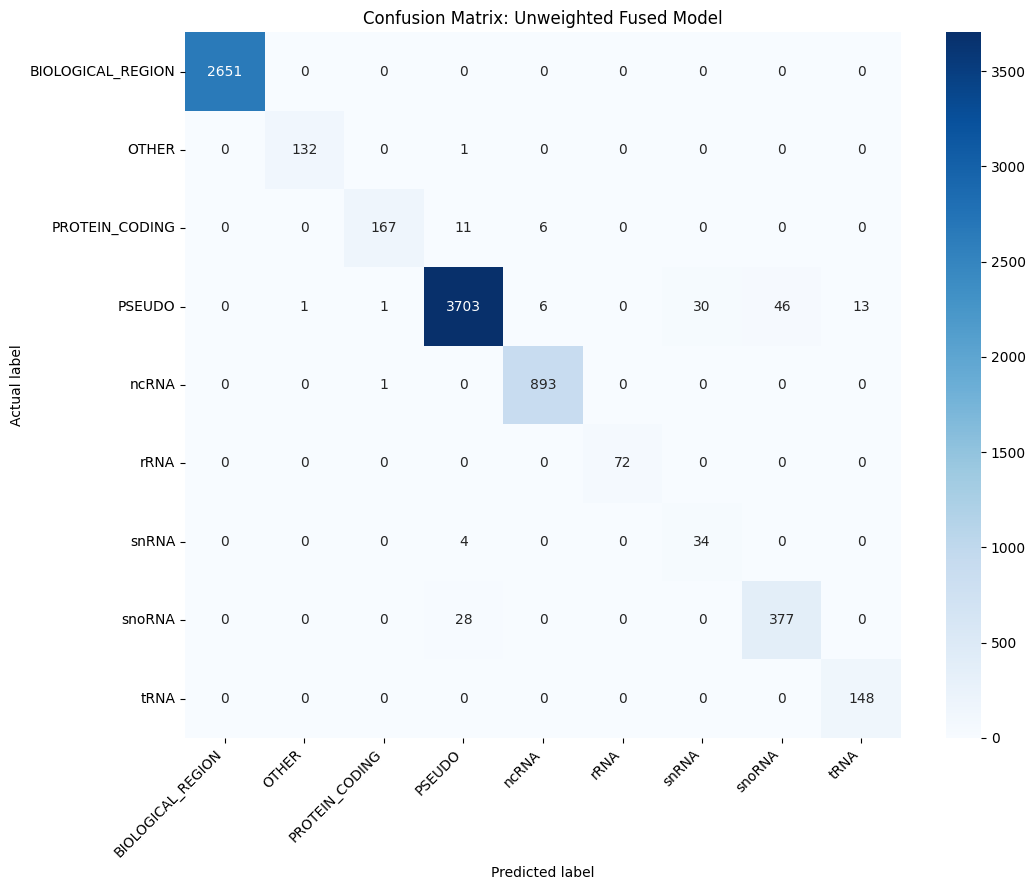

In [ ]:

cm = confusion_matrix(
    y_test,
    pred_classes,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cmap="Blues"
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix: Unweighted Fused Model")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

for cls, support, correct in zip(
    le.classes_,
    cm.sum(axis=1),
    np.diag(cm)
):
    print(
        f"{cls}: {support - correct} errors out of {support}"
    )

print("Total errors:", int(np.sum(pred_classes != y_test)))
print("Correct predictions:", int(np.sum(pred_classes == y_test)))


BIOLOGICAL_REGION: 0 errors out of 2651
OTHER: 1 errors out of 133
PROTEIN_CODING: 17 errors out of 184
PSEUDO: 97 errors out of 3800
ncRNA: 1 errors out of 894
rRNA: 0 errors out of 72
snRNA: 4 errors out of 38
snoRNA: 28 errors out of 405
tRNA: 0 errors out of 148
Total errors: 148
Correct predictions: 8177


In [ ]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

seq_input_lstm = Input(shape=(MAX_LEN,), name="dna_input_lstm")

x_lstm = Embedding(
    input_dim=len(dna_tokenizer.word_index) + 1,
    output_dim=8
)(seq_input_lstm)

x_lstm = LSTM(64)(x_lstm)
x_lstm = Dropout(0.3)(x_lstm)

x_lstm = Dense(128, activation="relu")(x_lstm)
x_lstm = Dropout(0.3)(x_lstm)

output_lstm = Dense(
    num_classes,
    activation="softmax"
)(x_lstm)

model_lstm = Model(
    inputs=seq_input_lstm,
    outputs=output_lstm
)

model_lstm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_lstm.summary()

history_lstm = model_lstm.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=50,
    batch_size=64,
    verbose=1
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dna_input_lstm (InputLayer)     │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 500, 8)         │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,225 (110.25 KB)

 Trainable params: 28,225 (110.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.4600 - loss: 1.4215 - val_accuracy: 0.4890 - val_loss: 1.3015
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4633 - loss: 1.3622 - val_accuracy: 0.4660 - val_loss: 1.3111
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4682 - loss: 1.3501 - val_accuracy: 0.4807 - val_loss: 1.3084
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4685 - loss: 1.3474 - val_accuracy: 0.4824 - val_loss: 1.3057
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4787 - loss: 1.3332 - val_accuracy: 0.5023 - val_loss: 1.2934
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.5193 - loss: 1.2794 - val_accuracy: 0.6666 - val_loss: 1.0120
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6538 - loss: 1.0420 - val_accuracy: 0.6683 - val_loss: 1.0105
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.5987 - loss: 1.1213 - val_accu

In [ ]:

pred_lstm = np.argmax(
    model_lstm.predict(X_test_seq, verbose=0),
    axis=1
)

lstm_accuracy = accuracy_score(y_test, pred_lstm)

print(f"LSTM-only accuracy: {lstm_accuracy:.6f}")
print(f"LSTM-only accuracy: {lstm_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_lstm,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


LSTM-only accuracy: 0.766727
LSTM-only accuracy: 76.67%

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     0.9597    0.8352    0.8931      2651
            OTHER     0.4505    0.3759    0.4098       133
   PROTEIN_CODING     0.0000    0.0000    0.0000       184
           PSEUDO     0.7574    0.8734    0.8113      3800
            ncRNA     0.5631    0.4743    0.5149       894
             rRNA     0.7031    0.6250    0.6618        72
            snRNA     0.0000    0.0000    0.0000        38
           snoRNA     0.5480    0.5358    0.5418       405
             tRNA     0.3654    0.7703    0.4957       148

         accuracy                         0.7667      8325
        macro avg     0.4830    0.4989    0.4809      8325
     weighted avg     0.7582    0.7667    0.7575      8325



In [ ]:

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

text_input_tfidf = Input(
    shape=(X_train_text.shape[1],),
    name="tfidf_input"
)

y_tfidf = Dense(256, activation="relu")(text_input_tfidf)
y_tfidf = Dropout(0.3)(y_tfidf)

y_tfidf = Dense(128, activation="relu")(y_tfidf)
y_tfidf = Dropout(0.3)(y_tfidf)

output_tfidf = Dense(
    num_classes,
    activation="softmax"
)(y_tfidf)

model_tfidf = Model(
    inputs=text_input_tfidf,
    outputs=output_tfidf
)

model_tfidf.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_tfidf.summary()

history_tfidf = model_tfidf.fit(
    X_train_text,
    y_train,
    validation_data=(X_val_text, y_val),
    epochs=50,
    batch_size=64,
    verbose=1
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tfidf_input (InputLayer)        │ (None, 3000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       768,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 802,313 (3.06 MB)

 Trainable params: 802,313 (3.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9013 - loss: 0.3852 - val_accuracy: 0.9757 - val_loss: 0.0725
Epoch 2/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9717 - loss: 0.0810 - val_accuracy: 0.9795 - val_loss: 0.0566
Epoch 3/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9758 - loss: 0.0652 - val_accuracy: 0.9797 - val_loss: 0.0543
Epoch 4/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9770 - loss: 0.0603 - val_accuracy: 0.9808 - val_loss: 0.0510
Epoch 5/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9787 - loss: 0.0572 - val_accuracy: 0.9810 - val_loss: 0.0495
Epoch 6/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9785 - loss: 0.0560 - val_accuracy: 0.9812 - val_loss: 0.0481
Epoch 7/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9790 - loss: 0.0523 - val_accuracy: 0.9803 - val_loss: 0.0490
Epoch 8/50
353/353 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9791 - loss: 0.0521 - val_accuracy: 0

In [ ]:

pred_tfidf = np.argmax(
    model_tfidf.predict(X_test_text, verbose=0),
    axis=1
)

tfidf_accuracy = accuracy_score(y_test, pred_tfidf)

print(f"TF-IDF-only accuracy: {tfidf_accuracy:.6f}")
print(f"TF-IDF-only accuracy: {tfidf_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_tfidf,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


TF-IDF-only accuracy: 0.981141
TF-IDF-only accuracy: 98.11%

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     1.0000    1.0000    1.0000      2651
            OTHER     0.9924    0.9850    0.9887       133
   PROTEIN_CODING     0.9639    0.8696    0.9143       184
           PSEUDO     0.9857    0.9763    0.9810      3800
            ncRNA     0.9717    0.9989    0.9851       894
             rRNA     1.0000    1.0000    1.0000        72
            snRNA     0.7027    0.6842    0.6933        38
           snoRNA     0.8913    0.9309    0.9106       405
             tRNA     0.9193    1.0000    0.9579       148

         accuracy                         0.9811      8325
        macro avg     0.9363    0.9383    0.9368      8325
     weighted avg     0.9814    0.9811    0.9811      8325



In [ ]:

logreg = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

logreg.fit(X_train_text, y_train)

pred_lr = logreg.predict(X_test_text)

accuracy_lr = accuracy_score(y_test, pred_lr)
weighted_f1_lr = f1_score(
    y_test, pred_lr, average="weighted"
)
macro_f1_lr = f1_score(
    y_test, pred_lr, average="macro"
)

print(f"Logistic Regression accuracy: {accuracy_lr:.6f}")
print(f"Logistic Regression accuracy: {accuracy_lr * 100:.2f}%")
print(f"Weighted F1: {weighted_f1_lr:.4f}")
print(f"Macro F1: {macro_f1_lr:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_lr,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Logistic Regression accuracy: 0.974895
Logistic Regression accuracy: 97.49%
Weighted F1: 0.9746
Macro F1: 0.9134

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     0.9996    1.0000    0.9998      2651
            OTHER     0.9429    0.9925    0.9670       133
   PROTEIN_CODING     0.9424    0.7120    0.8111       184
           PSEUDO     0.9785    0.9695    0.9740      3800
            ncRNA     0.9758    0.9933    0.9845       894
             rRNA     1.0000    1.0000    1.0000        72
            snRNA     0.6857    0.6316    0.6575        38
           snoRNA     0.8824    0.9630    0.9209       405
             tRNA     0.8471    0.9730    0.9057       148

         accuracy                         0.9749      8325
        macro avg     0.9172    0.9150    0.9134      8325
     weighted avg     0.9754    0.9749    0.9746      8325



In [ ]:

leak_terms = [
    "pseudogene", "regulatory region", "cis-regulatory", "enhancer",
    "small nucleolar", "small nuclear", "spliceosomal", "ribosomal",
    "microrna", "uncharacterized", "trna", "immunoglobulin",
    "t cell receptor", "histone", "olfactory receptor", "mpra"
]

def strip_leakage(text):
    cleaned = str(text).lower()

    for term in leak_terms:
        cleaned = cleaned.replace(term, "")

    return cleaned


train_descriptions_clean = train_df["Description"].apply(strip_leakage)
val_descriptions_clean = val_df["Description"].apply(strip_leakage)
test_descriptions_clean = test_df["Description"].apply(strip_leakage)

tfidf_clean = TfidfVectorizer(max_features=3000)

X_train_text_clean = tfidf_clean.fit_transform(
    train_descriptions_clean
).toarray()

X_val_text_clean = tfidf_clean.transform(
    val_descriptions_clean
).toarray()

X_test_text_clean = tfidf_clean.transform(
    test_descriptions_clean
).toarray()

logreg_clean = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

logreg_clean.fit(X_train_text_clean, y_train)

pred_lr_clean = logreg_clean.predict(X_test_text_clean)

accuracy_lr_clean = accuracy_score(y_test, pred_lr_clean)
weighted_f1_lr_clean = f1_score(
    y_test, pred_lr_clean, average="weighted"
)
macro_f1_lr_clean = f1_score(
    y_test, pred_lr_clean, average="macro"
)

print(f"Leakage-stripped Logistic Regression accuracy: {accuracy_lr_clean:.6f}")
print(f"Leakage-stripped accuracy: {accuracy_lr_clean * 100:.2f}%")
print(f"Weighted F1: {weighted_f1_lr_clean:.4f}")
print(f"Macro F1: {macro_f1_lr_clean:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_lr_clean,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    digits=4,
    zero_division=0
))


Leakage-stripped Logistic Regression accuracy: 0.940420
Leakage-stripped accuracy: 94.04%
Weighted F1: 0.9359
Macro F1: 0.7944

Classification report:
                   precision    recall  f1-score   support

BIOLOGICAL_REGION     0.9985    0.9977    0.9981      2651
            OTHER     0.8235    0.8421    0.8327       133
   PROTEIN_CODING     0.7536    0.2826    0.4111       184
           PSEUDO     0.9435    0.9318    0.9376      3800
            ncRNA     0.8488    0.9922    0.9149       894
             rRNA     0.9114    1.0000    0.9536        72
            snRNA     0.8750    0.1842    0.3043        38
           snoRNA     0.8842    0.9235    0.9034       405
             tRNA     0.8528    0.9392    0.8939       148

         accuracy                         0.9404      8325
        macro avg     0.8768    0.7881    0.7944      8325
     weighted avg     0.9396    0.9404    0.9359      8325



In [ ]:

results_summary = pd.DataFrame({
    "Model": [
        "Fused LSTM + TF-IDF (unweighted)",
        "LSTM-only (unweighted)",
        "Neural TF-IDF-only",
        "Logistic Regression (original text)",
        "Logistic Regression (leakage-stripped)"
    ],
    "Accuracy (%)": [
        fused_accuracy * 100,
        lstm_accuracy * 100,
        tfidf_accuracy * 100,
        accuracy_lr * 100,
        accuracy_lr_clean * 100
    ],
    "Weighted F1": [
        f1_score(y_test, pred_classes, average="weighted"),
        f1_score(y_test, pred_lstm, average="weighted"),
        f1_score(y_test, pred_tfidf, average="weighted"),
        weighted_f1_lr,
        weighted_f1_lr_clean
    ],
    "Macro F1": [
        f1_score(y_test, pred_classes, average="macro"),
        f1_score(y_test, pred_lstm, average="macro"),
        f1_score(y_test, pred_tfidf, average="macro"),
        macro_f1_lr,
        macro_f1_lr_clean
    ]
})

print(results_summary.to_string(index=False))


                                 Model  Accuracy (%)  Weighted F1  Macro F1
      Fused LSTM + TF-IDF (unweighted)     98.222222     0.982769  0.938663
                LSTM-only (unweighted)     76.672673     0.757451  0.480927
                    Neural TF-IDF-only     98.114114     0.981140  0.936769
   Logistic Regression (original text)     97.489489     0.974597  0.913391
Logistic Regression (leakage-stripped)     94.042042     0.935944  0.794411


In [ ]:
print("Model:", "model" in globals())
print("Training data:", "X_train_seq" in globals())
print("Predictions:", "pred_classes" in globals())
print("History:", "history" in globals())

Model: True
Training data: True
Predictions: True
History: True


In [ ]:
cm = confusion_matrix(
    y_test,
    pred_classes,
    labels=np.arange(num_classes)
)

names = le.classes_

print("FULL CONFUSION MATRIX:")
print(pd.DataFrame(cm, index=names, columns=names).to_string())

print("\nOFF-DIAGONAL ERRORS:")
for i, actual in enumerate(names):
    for j, predicted in enumerate(names):
        if i != j and cm[i, j] > 0:
            print(f"{actual} -> {predicted}: {cm[i, j]}")

print("\nFALSE POSITIVES BY PREDICTED CLASS:")
for j, predicted in enumerate(names):
    print(
        f"Predicted as {predicted}: "
        f"{cm[:, j].sum() - cm[j, j]}"
    )

FULL CONFUSION MATRIX:
                   BIOLOGICAL_REGION  OTHER  PROTEIN_CODING  PSEUDO  ncRNA  rRNA  snRNA  snoRNA  tRNA
BIOLOGICAL_REGION               2651      0               0       0      0     0      0       0     0
OTHER                              0    132               0       1      0     0      0       0     0
PROTEIN_CODING                     0      0             167      11      6     0      0       0     0
PSEUDO                             0      1               1    3703      6     0     30      46    13
ncRNA                              0      0               1       0    893     0      0       0     0
rRNA                               0      0               0       0      0    72      0       0     0
snRNA                              0      0               0       4      0     0     34       0     0
snoRNA                             0      0               0      28      0     0      0     377     0
tRNA                               0      0               0

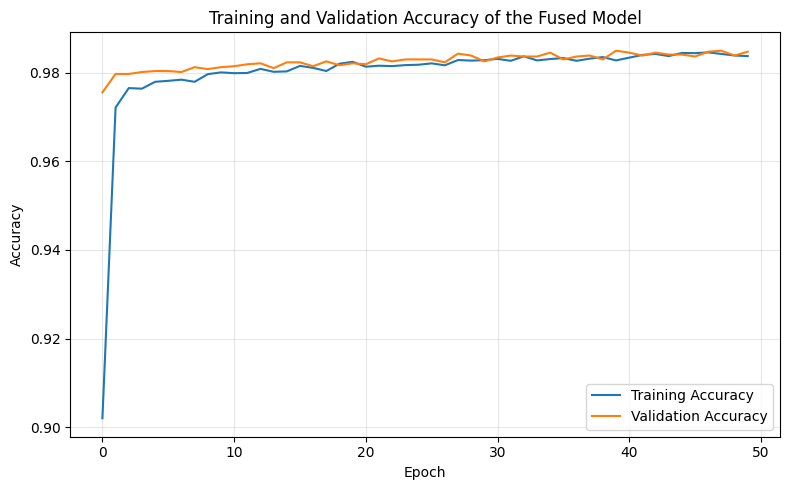

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy of the Fused Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("fig2_fused_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#from google.colab import files
#files.download("fig2_fused_accuracy.png")

In [ ]:
def build_fused():
    seq_in = Input(shape=(MAX_LEN,))
    x = LSTM(64)(
        Embedding(len(dna_tokenizer.word_index) + 1, 8)(seq_in)
    )
    x = Dropout(0.3)(x)

    txt_in = Input(shape=(X_train_text.shape[1],))
    y = Dropout(0.3)(Dense(256, activation="relu")(txt_in))

    z = Dropout(0.3)(
        Dense(128, activation="relu")(Concatenate()([x, y]))
    )

    out = Dense(num_classes, activation="softmax")(z)

    m = Model([seq_in, txt_in], out)
    m.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return m


def build_tfidf():
    txt_in = Input(shape=(X_train_text.shape[1],))
    y = Dropout(0.3)(Dense(256, activation="relu")(txt_in))
    y = Dropout(0.3)(Dense(128, activation="relu")(y))
    out = Dense(num_classes, activation="softmax")(y)

    m = Model(txt_in, out)
    m.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return m


seed_results = {"Fused": [], "TF-IDF-only": []}

for seed in [0, 1]:
    # Fused model
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    m = build_fused()
    m.fit(
        [X_train_seq, X_train_text],
        y_train,
        epochs=50,
        batch_size=64,
        verbose=0
    )

    p = np.argmax(
        m.predict([X_test_seq, X_test_text], verbose=0),
        axis=1
    )
    seed_results["Fused"].append(accuracy_score(y_test, p))

    # TF-IDF-only model
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    m = build_tfidf()
    m.fit(
        X_train_text,
        y_train,
        epochs=50,
        batch_size=64,
        verbose=0
    )

    p = np.argmax(m.predict(X_test_text, verbose=0), axis=1)
    seed_results["TF-IDF-only"].append(accuracy_score(y_test, p))

    print(f"Seed {seed} completed.")
    print({
        name: round(values[-1] * 100, 2)
        for name, values in seed_results.items()
    })


for name, accs in seed_results.items():
    a = np.array(accs) * 100
    print(
        f"{name}: {np.round(a, 2)} | "
        f"Mean: {a.mean():.2f}% | "
        f"Sample SD: {a.std(ddof=1):.2f}"
    )

Seed 0 completed.
{'Fused': 98.47, 'TF-IDF-only': 98.2}
Seed 1 completed.
{'Fused': 97.89, 'TF-IDF-only': 98.05}
Fused: [98.47 97.89] | Mean: 98.18% | Sample SD: 0.42
TF-IDF-only: [98.2  98.05] | Mean: 98.13% | Sample SD: 0.10


In [ ]:
print("Partial results:", seed_results if "seed_results" in globals() else "No results saved")
print("Original model available:", "model" in globals())
print("Original history available:", "history" in globals())

Partial results: No results saved
Original model available: True
Original history available: True
